# Image Classification of CIFAR-10 bằng CNN

Notebook trình bày lại quy trình phân loại ảnh CIFAR-10 bằng TensorFlow/Keras

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Nạp và xử lý dữ liệu

CIFAR-10 gồm 10 nhóm ảnh màu có kích thước 32x32. Giá trị điểm ảnh được đưa về khoảng `[0, 1]` để quá trình tối ưu ổn định hơn.

In [2]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train = y_train.squeeze()
y_test = y_test.squeeze()

print(f'Tập huấn luyện: {x_train.shape[0]:,} ảnh')
print(f'Tập kiểm tra: {x_test.shape[0]:,} ảnh')
print(f'Kích thước ảnh: {x_train.shape[1:]}')

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 235s 1us/step
Tập huấn luyện: 50,000 ảnh
Tập kiểm tra: 10,000 ảnh
Kích thước ảnh: (32, 32, 3)


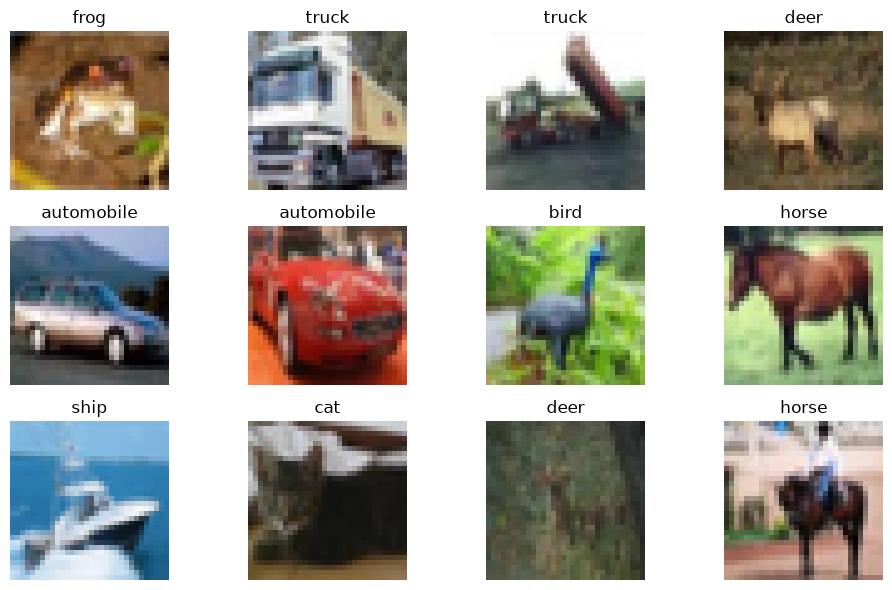

In [3]:
plt.figure(figsize=(10, 6))
for index in range(12):
    plt.subplot(3, 4, index + 1)
    plt.imshow(x_train[index])
    plt.title(class_names[y_train[index]])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Xây dựng mô hình CNN

Mô hình sử dụng hai khối `Conv2D` kết hợp `MaxPooling2D`, sau đó chuyển đặc trưng sang các lớp đầy đủ. Lớp `Dropout` giúp giảm nguy cơ học thuộc dữ liệu huấn luyện.

In [4]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Huấn luyện

Lịch sử huấn luyện được lưu lại để đối chiếu chất lượng mô hình trên hai tập dữ liệu.

In [5]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.3639 - loss: 1.7409 - val_accuracy: 0.5256 - val_loss: 1.3602
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.4988 - loss: 1.3906 - val_accuracy: 0.5716 - val_loss: 1.1716
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.5570 - loss: 1.2409 - val_accuracy: 0.6212 - val_loss: 1.0855
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.5955 - loss: 1.1316 - val_accuracy: 0.6604 - val_loss: 0.9755
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6261 - loss: 1.0509 - val_accuracy: 0.6986 - val_loss: 0.8678
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6501 - loss: 0.9808 - val_accuracy: 0.7048 - val_loss: 0.8495
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6719 - loss: 0.9256 - val_accuracy: 0.7224 - val_loss: 0.7916
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6877 - loss: 0.8787 - val_a

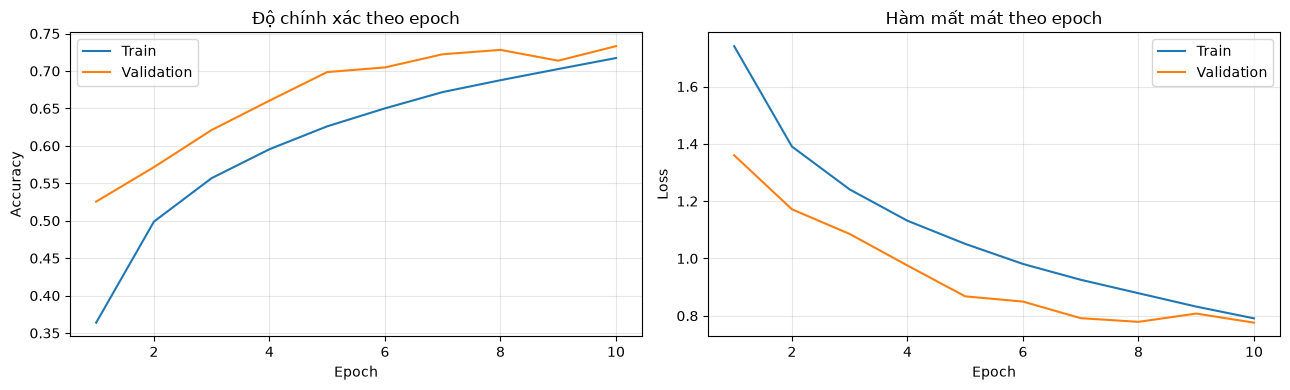

In [6]:
history_values = history.history
epochs = range(1, len(history_values['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs, history_values['accuracy'], label='Train')
axes[0].plot(epochs, history_values['val_accuracy'], label='Validation')
axes[0].set_title('Độ chính xác theo epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history_values['loss'], label='Train')
axes[1].plot(epochs, history_values['val_loss'], label='Validation')
axes[1].set_title('Hàm mất mát theo epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Đánh giá trên tập kiểm tra

Ngoài accuracy và loss tổng quát, báo cáo dưới đây cung cấp precision, recall và F1-score cho từng lớp. Ma trận nhầm lẫn giúp quan sát những cặp lớp mà mô hình dễ dự đoán sai.

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f'Loss trên tập kiểm tra: {test_loss:.4f}')
print(f'Accuracy trên tập kiểm tra: {test_accuracy:.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Loss trên tập kiểm tra: 0.8078
Accuracy trên tập kiểm tra: 0.7187

Classification report:
              precision    recall  f1-score   support

    airplane     0.7528    0.7950    0.7733      1000
  automobile     0.8272    0.8570    0.8418      1000
        bird     0.5528    0.6440    0.5949      1000
         cat     0.5197    0.5270    0.5233      1000
        deer     0.7100    0.5730    0.6342      1000
         dog     0.6107    0.6290    0.6197      1000
        frog     0.8804    0.7140    0.7885      1000
       horse     0.7702    0.7810    0.7756      1000
        ship     0.8529    0.8290    0.8408      1000
       truck     0.7653    0.8380    0.8000      1000

    accuracy                         0.7187     10000
   macro avg     0.7242    0.7187    0.7192     10000
weighted avg     0.7242    0.7187    0.7192     10000



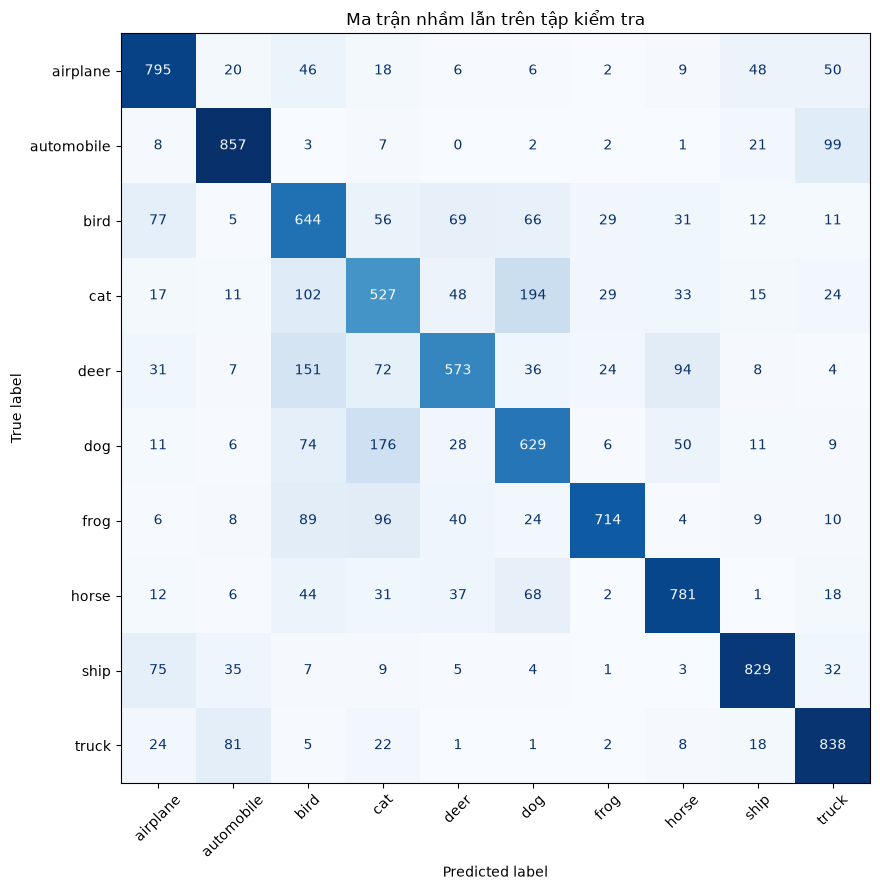

In [8]:
matrix = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9, 9))
display.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title('Ma trận nhầm lẫn trên tập kiểm tra')
plt.tight_layout()
plt.show()

## 5. Báo cáo kết quả

### Tóm tắt

- Dữ liệu được chuẩn hóa trước khi đưa vào mạng.
- CNN học đặc trưng ảnh qua các lớp tích chập và giảm kích thước bằng pooling.
- Accuracy và loss của tập huấn luyện/validation được theo dõi qua từng epoch.
- Classification report cho biết hiệu quả theo từng nhóm ảnh, còn confusion matrix cho thấy các lỗi dự đoán phổ biến.

### Nhận xét

Kết quả cuối cùng cần được đọc cùng với khoảng cách giữa accuracy huấn luyện và validation. Nếu khoảng cách lớn, mô hình có dấu hiệu overfitting; khi đó có thể tăng augmentation, điều chỉnh Dropout hoặc dùng EarlyStopping. Các lớp có F1-score thấp và thường bị nhầm lẫn trong ma trận là những lớp nên được ưu tiên cải thiện.